In [2]:
import sys

print(sys.version)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]


In [3]:
import pandas as pd

print(pd.__version__)

2.2.3


In [4]:
df = pd.read_csv("../data/Sample - Superstore.csv", encoding="windows-1252")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.shape

(9994, 21)

In [6]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [8]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [11]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

In [12]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month_name()
df["Order Month Number"] = df["Order Date"].dt.month

In [13]:
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

In [14]:
df["Profit Margin"] = df["Profit"] / df["Sales"]

In [15]:
df[[
    "Order Date",
    "Ship Date",
    "Order Year",
    "Order Month",
    "Shipping Days",
    "Sales",
    "Profit",
    "Profit Margin"
]].head()

,Order Date,Ship Date,Order Year,Order Month,Shipping Days,Sales,Profit,Profit Margin
0,2016-11-08,2016-11-11,2016,November,3,261.9600,41.9136,0.1600
1,2016-11-08,2016-11-11,2016,November,3,731.9400,219.5820,0.3000
2,2016-06-12,2016-06-16,2016,June,4,14.6200,6.8714,0.4700
3,2015-10-11,2015-10-18,2015,October,7,957.5775,-383.0310,-0.4000
4,2015-10-11,2015-10-18,2015,October,7,22.3680,2.5164,0.1125


In [16]:
df[["Shipping Days", "Sales", "Quantity", "Discount", "Profit", "Profit Margin"]].describe()

,Shipping Days,Sales,Quantity,Discount,Profit,Profit Margin
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,3.958175,229.858001,3.789574,0.156203,28.656896,0.120314
std,1.747567,623.245101,2.225110,0.206452,234.260108,0.466754
min,0.000000,0.444000,1.000000,0.000000,-6599.978000,-2.750000
25%,3.000000,17.280000,2.000000,0.000000,1.728750,0.075000
50%,4.000000,54.490000,3.000000,0.200000,8.666500,0.270000
75%,5.000000,209.940000,5.000000,0.200000,29.364000,0.362500
max,7.000000,22638.480000,14.000000,0.800000,8399.976000,0.500000


In [17]:
df["Order Date"].min(), df["Order Date"].max()

(Timestamp('2014-01-03 00:00:00'), Timestamp('2017-12-30 00:00:00'))

# Exploratory Data Analysis

## Company-Level KPIs

Before investigating individual products, customers, regions, and trends, this section establishes baseline company performance across the full dataset.

In [18]:
total_sales = df["Sales"].sum()

print(f"Total Sales: ${total_sales:,.2f}")

Total Sales: $2,297,200.86


In [19]:
total_profit = df["Profit"].sum()

print(f"Total Profit: ${total_profit:,.2f}")

Total Profit: $286,397.02


In [20]:
profit_margin = total_profit / total_sales

print(f"Profit Margin: {profit_margin:.2%}")

Profit Margin: 12.47%


In [21]:
total_orders = df["Order ID"].nunique()

print(f"Total Orders: {total_orders:,}")

Total Orders: 5,009


In [22]:
total_customers = df["Customer ID"].nunique()

print(f"Total Customers: {total_customers:,}")

Total Customers: 793


In [23]:
average_order_value = total_sales / total_orders

print(f"Average Order Value: ${average_order_value:,.2f}")

Average Order Value: $458.61


In [24]:
print("COMPANY PERFORMANCE SUMMARY")
print("---------------------------")
print(f"Total Sales:         ${total_sales:,.2f}")
print(f"Total Profit:        ${total_profit:,.2f}")
print(f"Profit Margin:        {profit_margin:.2%}")
print(f"Total Orders:         {total_orders:,}")
print(f"Total Customers:      {total_customers:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

COMPANY PERFORMANCE SUMMARY
---------------------------
Total Sales:         $2,297,200.86
Total Profit:        $286,397.02
Profit Margin:        12.47%
Total Orders:         5,009
Total Customers:      793
Average Order Value: $458.61


## Sales and Profit Trends

This section evaluates how company performance changed over time, including annual sales, profit, profit margin, and year-over-year growth.

In [25]:
yearly_performance = (
    df.groupby("Order Year")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
)

yearly_performance

,Sales,Profit
Order Year,,
2014,484247.4981,49543.9741
2015,470532.5090,61618.6037
2016,609205.5980,81795.1743
2017,733215.2552,93439.2696


In [26]:
yearly_performance["Profit Margin"] = (
    yearly_performance["Profit"] / yearly_performance["Sales"]
)

yearly_performance

,Sales,Profit,Profit Margin
Order Year,,,
2014,484247.4981,49543.9741,0.102311
2015,470532.5090,61618.6037,0.130955
2016,609205.5980,81795.1743,0.134265
2017,733215.2552,93439.2696,0.127438


In [27]:
yearly_performance["Sales Growth"] = (
    yearly_performance["Sales"].pct_change()
)

yearly_performance["Profit Growth"] = (
    yearly_performance["Profit"].pct_change()
)

yearly_performance

,Sales,Profit,Profit Margin,Sales Growth,Profit Growth
Order Year,,,,,
2014,484247.4981,49543.9741,0.102311,NaN,NaN
2015,470532.5090,61618.6037,0.130955,-0.028322,0.243715
2016,609205.5980,81795.1743,0.134265,0.294715,0.327443
2017,733215.2552,93439.2696,0.127438,0.203560,0.142357


In [28]:
yearly_display = yearly_performance.copy()

yearly_display["Sales"] = yearly_display["Sales"].map("${:,.2f}".format)
yearly_display["Profit"] = yearly_display["Profit"].map("${:,.2f}".format)
yearly_display["Profit Margin"] = yearly_display["Profit Margin"].map("{:.2%}".format)
yearly_display["Sales Growth"] = yearly_display["Sales Growth"].map(
    lambda x: f"{x:.2%}" if pd.notna(x) else "N/A"
)
yearly_display["Profit Growth"] = yearly_display["Profit Growth"].map(
    lambda x: f"{x:.2%}" if pd.notna(x) else "N/A"
)

yearly_display

,Sales,Profit,Profit Margin,Sales Growth,Profit Growth
Order Year,,,,,
2014,"$484,247.50","$49,543.97",10.23%,N/A,N/A
2015,"$470,532.51","$61,618.60",13.10%,-2.83%,24.37%
2016,"$609,205.60","$81,795.17",13.43%,29.47%,32.74%
2017,"$733,215.26","$93,439.27",12.74%,20.36%,14.24%


In [29]:
import matplotlib.pyplot as plt

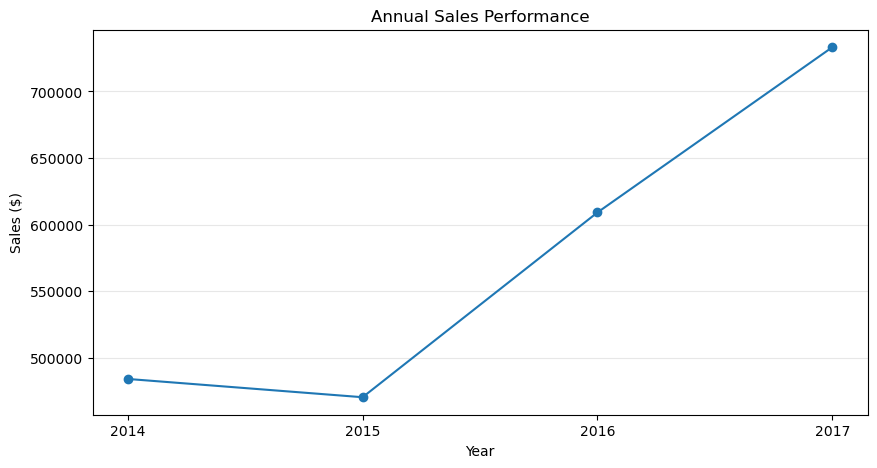

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_performance.index,
    yearly_performance["Sales"],
    marker="o"
)

plt.title("Annual Sales Performance")
plt.xlabel("Year")
plt.ylabel("Sales ($)")
plt.xticks(yearly_performance.index)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Key Findings

- Sales declined **2.83% in 2015**, while profit increased **24.37%**, improving the annual profit margin from **10.23% to 13.10%**.

- Performance accelerated substantially in **2016**, with sales increasing **29.47%** and profit increasing **32.74%**.

- **2017 was the strongest year for overall performance**, generating **USD 733,215 in sales** and **USD 93,439 in profit**.

- Despite record sales and profit in 2017, sales grew **20.36%** while profit grew only **14.24%**. As a result, profit margin declined from **13.43% to 12.74%**, indicating that profitability did not keep pace with revenue growth.

## Category Performance

This section evaluates sales and profitability across product categories to identify which areas of the business contribute most strongly to overall performance.

In [31]:
category_performance = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
)

category_performance

,Sales,Profit,Quantity
Category,,,
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906
Technology,836154.0330,145454.9481,6939


In [32]:
category_performance["Profit Margin"] = (
    category_performance["Profit"] /
    category_performance["Sales"]
)

category_performance

,Sales,Profit,Quantity,Profit Margin
Category,,,,
Furniture,741999.7953,18451.2728,8028,0.024867
Office Supplies,719047.0320,122490.8008,22906,0.170352
Technology,836154.0330,145454.9481,6939,0.173957


In [33]:
category_performance["Sales Share"] = (
    category_performance["Sales"] / total_sales
)

category_performance["Profit Share"] = (
    category_performance["Profit"] / total_profit
)

category_performance

,Sales,Profit,Quantity,Profit Margin,Sales Share,Profit Share
Category,,,,,,
Furniture,741999.7953,18451.2728,8028,0.024867,0.323002,0.064426
Office Supplies,719047.0320,122490.8008,22906,0.170352,0.313010,0.427696
Technology,836154.0330,145454.9481,6939,0.173957,0.363988,0.507879


In [34]:
category_display = category_performance.copy()

category_display["Sales"] = category_display["Sales"].map("${:,.2f}".format)
category_display["Profit"] = category_display["Profit"].map("${:,.2f}".format)
category_display["Quantity"] = category_display["Quantity"].map("{:,}".format)
category_display["Profit Margin"] = category_display["Profit Margin"].map("{:.2%}".format)
category_display["Sales Share"] = category_display["Sales Share"].map("{:.2%}".format)
category_display["Profit Share"] = category_display["Profit Share"].map("{:.2%}".format)

category_display

,Sales,Profit,Quantity,Profit Margin,Sales Share,Profit Share
Category,,,,,,
Furniture,"$741,999.80","$18,451.27","8,028",2.49%,32.30%,6.44%
Office Supplies,"$719,047.03","$122,490.80","22,906",17.04%,31.30%,42.77%
Technology,"$836,154.03","$145,454.95","6,939",17.40%,36.40%,50.79%


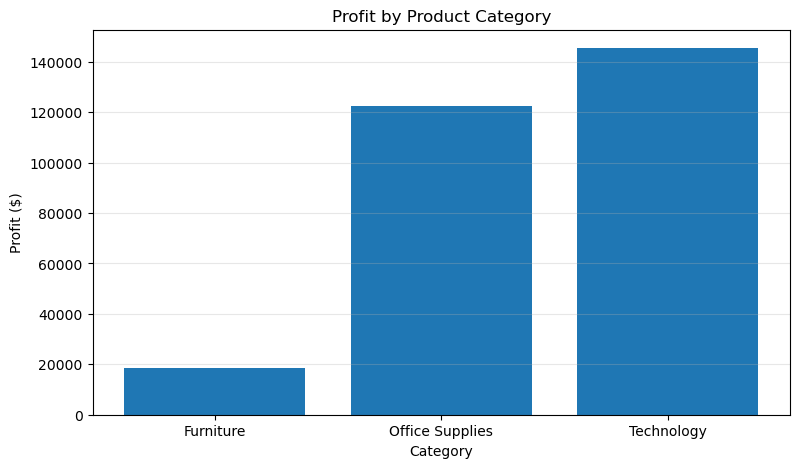

In [35]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_performance.index,
    category_performance["Profit"]
)

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit ($)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Key Finding: Furniture Underperformance

Furniture generated **USD 742,000 in sales**, representing **32.3% of company revenue**, but contributed only **USD 18,451 in profit**, or **6.4% of total company profit**. Its **2.49% profit margin** substantially trails Office Supplies (17.04%) and Technology (17.40%).

This indicates that Furniture's weak profitability warrants further investigation at the sub-category and product levels.

## Sub-Category Performance

To identify the drivers of category-level profitability, this section evaluates sales, profit, and profit margins across individual product sub-categories.

In [36]:
subcategory_performance = (
    df.groupby(["Category", "Sub-Category"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
)

subcategory_performance["Profit Margin"] = (
    subcategory_performance["Profit"] /
    subcategory_performance["Sales"]
)

subcategory_performance

Sales      Profit  Quantity  Profit Margin
Category        Sub-Category                                                  
Furniture       Bookcases     114879.9963  -3472.5560       868      -0.030228
                Chairs        328449.1030  26590.1663      2356       0.080957
                Furnishings    91705.1640  13059.1436      3563       0.142404
                Tables        206965.5320 -17725.4811      1241      -0.085645
Office Supplies Appliances    107532.1610  18138.0054      1729       0.168675
                Art            27118.7920   6527.7870      3000       0.240711
                Binders       203412.7330  30221.7633      5974       0.148574
                Envelopes      16476.4020   6964.1767       906       0.422676
                Fasteners       3024.2800    949.5182       914       0.313965
                Labels         12486.3120   5546.2540      1400       0.444187
                Paper          78479.2060  34053.5693      5178       0.433918
                Storage       223843.6080  21278.8264      3158       0.095061
                Supplies       46673.5380  -1189.0995       647      -0.025477
Technology      Accessories   167380.3180  41936.6357      2976       0.250547
                Copiers       149528.0300  55617.8249       234       0.371956
                Machines      189238.6310   3384.7569       440       0.017886
                Phones        330007.0540  44515.7306      3289       0.134893

In [37]:
subcategory_sorted = (
    subcategory_performance
    .reset_index()
    .sort_values("Profit")
)

subcategory_sorted[[
    "Category",
    "Sub-Category",
    "Sales",
    "Profit",
    "Profit Margin"
]]

,Category,Sub-Category,Sales,Profit,Profit Margin
3,Furniture,Tables,206965.5320,-17725.4811,-0.085645
0,Furniture,Bookcases,114879.9963,-3472.5560,-0.030228
12,Office Supplies,Supplies,46673.5380,-1189.0995,-0.025477
8,Office Supplies,Fasteners,3024.2800,949.5182,0.313965
15,Technology,Machines,189238.6310,3384.7569,0.017886
9,Office Supplies,Labels,12486.3120,5546.2540,0.444187
5,Office Supplies,Art,27118.7920,6527.7870,0.240711
7,Office Supplies,Envelopes,16476.4020,6964.1767,0.422676
2,Furniture,Furnishings,91705.1640,13059.1436,0.142404
4,Office Supplies,Appliances,107532.1610,18138.0054,0.168675


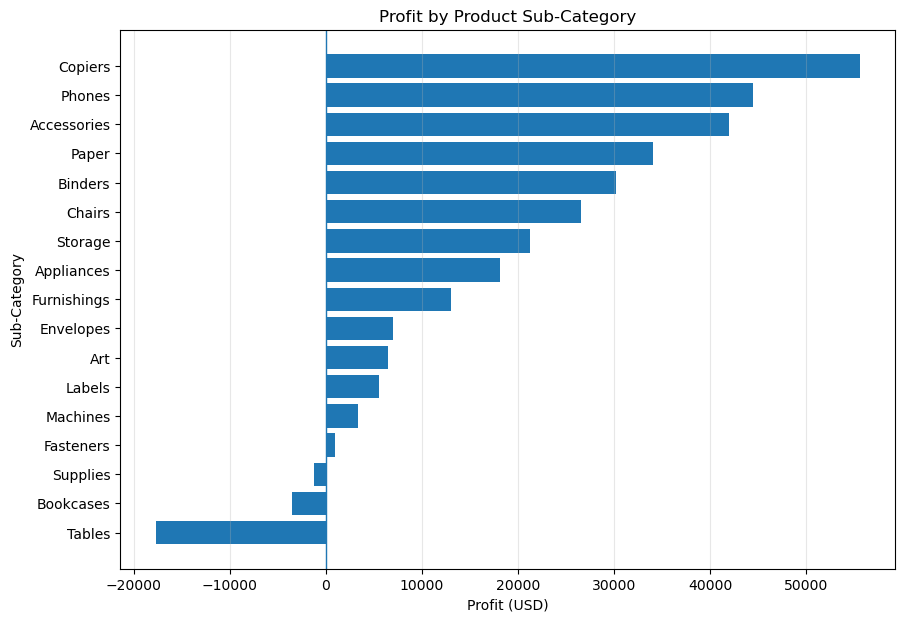

In [38]:
subcategory_chart = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    subcategory_chart.index,
    subcategory_chart.values
)

plt.title("Profit by Product Sub-Category")
plt.xlabel("Profit (USD)")
plt.ylabel("Sub-Category")
plt.axvline(0, linewidth=1)
plt.grid(axis="x", alpha=0.3)

plt.show()

## Discount and Profitability Analysis

This section investigates whether higher discount levels are associated with lower profit margins, particularly in underperforming product sub-categories.

In [39]:
discount_performance = (
    df.groupby("Discount")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
)

discount_performance["Profit Margin"] = (
    discount_performance["Profit"] /
    discount_performance["Sales"]
)

discount_performance

,Sales,Profit,Orders,Profit Margin
Discount,,,,
0.00,1.087908e+06,320987.6032,2644,0.295050
0.10,5.436935e+04,9029.1770,89,0.166071
0.15,2.755852e+04,1418.9915,51,0.051490
0.20,7.645944e+05,90337.3060,2407,0.118151
0.30,1.032267e+05,-10369.2774,211,-0.100452
0.32,1.449346e+04,-2391.1377,27,-0.164980
0.40,1.164178e+05,-23057.0504,185,-0.198054
0.45,5.484974e+03,-2493.1111,10,-0.454535
0.50,5.891854e+04,-20506.4281,64,-0.348047


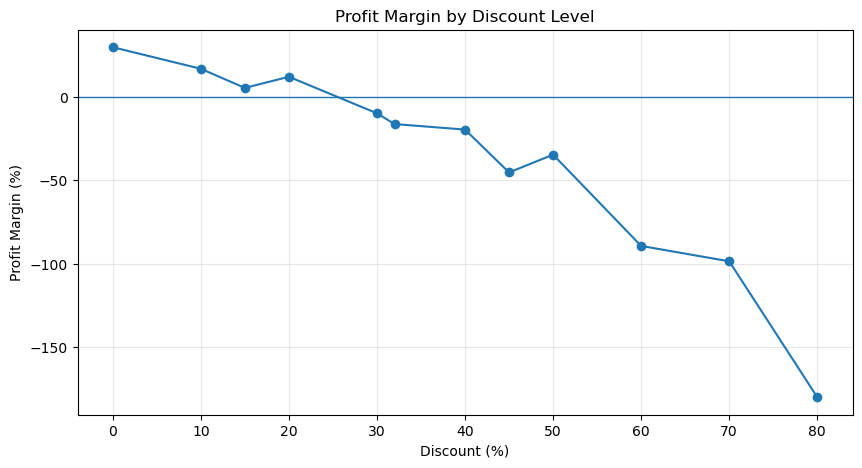

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    discount_performance.index * 100,
    discount_performance["Profit Margin"] * 100,
    marker="o"
)

plt.axhline(0, linewidth=1)

plt.title("Profit Margin by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.grid(alpha=0.3)

plt.show()

### Furniture Discount Investigation

This analysis compares discount levels and profitability across Furniture sub-categories to investigate whether loss-making products are associated with heavier discounting.

In [41]:
furniture_discounts = (
    df[df["Category"] == "Furniture"]
    .groupby("Sub-Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean"),
        Transactions=("Row ID", "count")
    )
)

furniture_discounts["Profit Margin"] = (
    furniture_discounts["Profit"] /
    furniture_discounts["Sales"]
)

furniture_discounts.sort_values("Profit")

,Sales,Profit,Average_Discount,Transactions,Profit Margin
Sub-Category,,,,,
Tables,206965.5320,-17725.4811,0.261285,319,-0.085645
Bookcases,114879.9963,-3472.5560,0.211140,228,-0.030228
Furnishings,91705.1640,13059.1436,0.138349,957,0.142404
Chairs,328449.1030,26590.1663,0.170178,617,0.080957


### Key Finding: Discounting and Furniture Profitability

The analysis identified a negative relationship between average discount levels and profit margins across Furniture sub-categories.

- **Tables:** Average discount of **26.13%**, generating a **USD 17,725 loss** and a **-8.56% profit margin**.
- **Bookcases:** Average discount of **21.11%**, generating a **USD 3,473 loss** and a **-3.02% profit margin**.
- **Chairs:** Average discount of **17.02%**, generating **USD 26,590 in profit** with an **8.10% margin**.
- **Furnishings:** Average discount of **13.83%**, generating **USD 13,059 in profit** with a **14.24% margin**.

**Business implication:** Higher discount levels are associated with weaker profitability in Furniture, particularly Tables and Bookcases. Management should review discount policies and product-level costs before making pricing changes.

## Regional Sales and Profitability Analysis

This section compares revenue, profit, and profit margins across geographic regions to identify areas of strong performance and potential opportunities for improvement.

In [42]:
regional_performance = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
)

regional_performance["Profit Margin"] = (
    regional_performance["Profit"] /
    regional_performance["Sales"]
)

regional_performance.sort_values("Profit", ascending=False)

,Sales,Profit,Orders,Profit Margin
Region,,,,
West,725457.8245,108418.4489,1611,0.149448
East,678781.2400,91522.7800,1401,0.134834
South,391721.9050,46749.4303,822,0.119343
Central,501239.8908,39706.3625,1175,0.079216


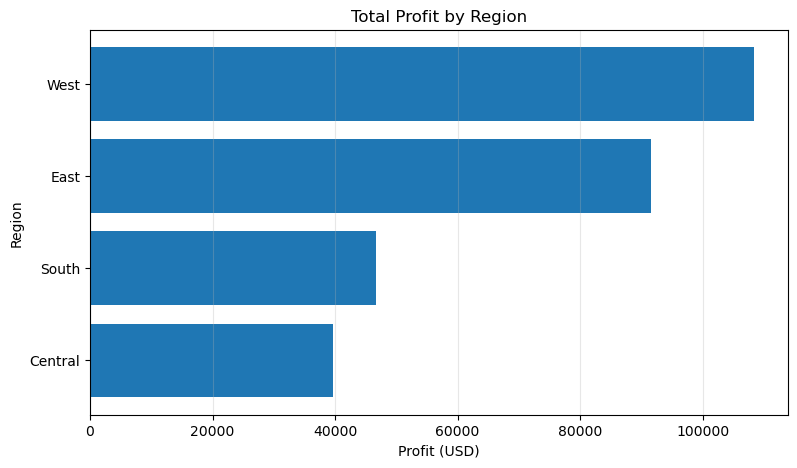

In [43]:
regional_chart = (
    regional_performance["Profit"]
    .sort_values()
)

plt.figure(figsize=(9, 5))

plt.barh(
    regional_chart.index,
    regional_chart.values
)

plt.title("Total Profit by Region")
plt.xlabel("Profit (USD)")
plt.ylabel("Region")
plt.grid(axis="x", alpha=0.3)

plt.show()

### Key Finding: Regional Profitability Differences

The **West region** generated the highest sales (USD 725,458) and profit (USD 108,418), achieving a **14.94% profit margin**.

In contrast, the **Central region** generated approximately **USD 501,240 in sales** but only **USD 39,706 in profit**, resulting in the lowest regional profit margin of **7.92%**.

Despite generating more revenue than the South region, Central earned less profit, suggesting that its profitability warrants further investigation.

**Business implication:** Management should investigate product mix, discounting, and other potential drivers of Central's lower profitability before determining corrective actions.

## Customer Analysis

This section evaluates customer purchasing behavior, revenue contribution, and profitability to identify high-value customers and potential revenue concentration risks.

In [45]:
customer_performance = (
    df.groupby(["Customer ID", "Customer Name"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
)

customer_performance["Profit Margin"] = (
    customer_performance["Profit"] /
    customer_performance["Sales"]
)

customer_performance = customer_performance.sort_values(
    "Sales", ascending=False
)

customer_performance.head(10)

,,Sales,Profit,Orders,Profit Margin
Customer ID,Customer Name,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5,-0.079093
TC-20980,Tamara Chand,19052.218,8981.3239,5,0.471406
RB-19360,Raymond Buch,15117.339,6976.0959,6,0.461463
TA-21385,Tom Ashbrook,14595.620,4703.7883,4,0.322274
AB-10105,Adrian Barton,14473.571,5444.8055,10,0.376190
KL-16645,Ken Lonsdale,14175.229,806.8550,12,0.056920
SC-20095,Sanjit Chand,14142.334,5757.4119,9,0.407105
HL-15040,Hunter Lopez,12873.298,5622.4292,6,0.436751
SE-20110,Sanjit Engle,12209.438,2650.6769,11,0.217101


In [46]:
top_10_sales = customer_performance.head(10)["Sales"].sum()

top_10_sales_share = top_10_sales / total_sales

print(f"Revenue from Top 10 Customers: USD {top_10_sales:,.2f}")
print(f"Share of Total Revenue: {top_10_sales_share:.2%}")

Revenue from Top 10 Customers: USD 153,811.17
Share of Total Revenue: 6.70%


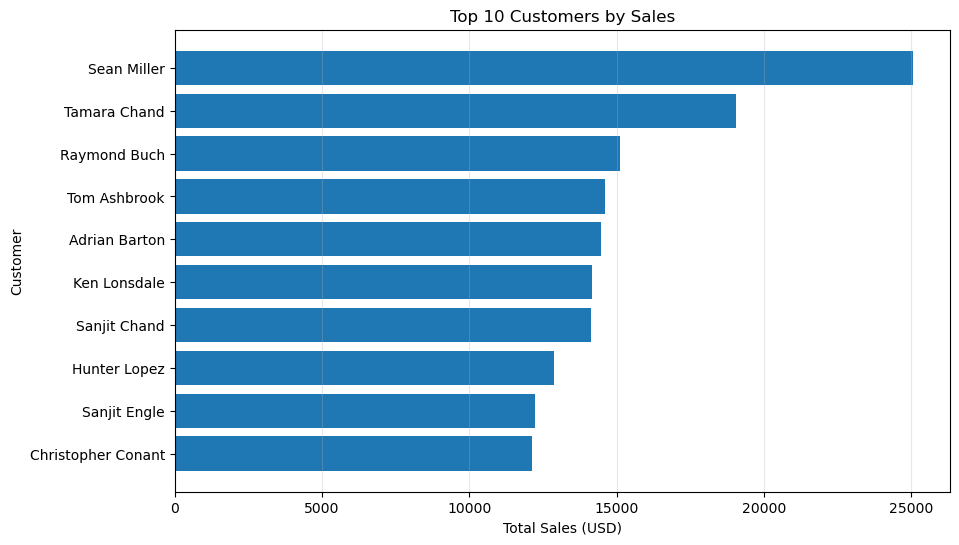

In [47]:
top_customers = (
    customer_performance.head(10)
    .reset_index()
    .sort_values("Sales")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_customers["Customer Name"],
    top_customers["Sales"]
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales (USD)")
plt.ylabel("Customer")
plt.grid(axis="x", alpha=0.3)

plt.show()

### Key Finding: Customer Revenue and Profitability

The ten highest-spending customers generated approximately **USD 153,811**, representing **6.70% of total company revenue**. This indicates relatively limited revenue concentration among the ten largest customers.

However, high customer spending did not necessarily translate into profitability.

- **Sean Miller:** Generated **USD 25,043 in sales** but produced a **USD 1,981 loss**, resulting in a **-7.91% profit margin**.
- **Tamara Chand:** Generated **USD 19,052 in sales** and **USD 8,981 in profit**, achieving a **47.14% margin**.
- **Raymond Buch:** Generated **USD 15,117 in sales** and **USD 6,976 in profit**, achieving a **46.15% margin**.

**Business implication:** Customer performance should be evaluated using both revenue and profit. Management should investigate loss-making customer accounts and their product purchases, discounts, and associated costs before considering pricing or account-management changes.

## Executive Summary and Business Recommendations

### Project Overview

Analyzed 9,994 retail sales records spanning 2014–2017 using Python and pandas to evaluate revenue, profitability, product performance, discounting, geographic trends, and customer behavior.

### Key Business Findings

1. **Overall Performance:** The company generated approximately **USD 2.30 million in sales** and **USD 286,397 in profit**, achieving a **12.47% overall profit margin**.

2. **Revenue Growth:** Sales increased by **29.47% in 2016** and **20.36% in 2017**. However, profit margin declined from **13.43% to 12.74%** in 2017, indicating that profitability did not keep pace with revenue growth.

3. **Furniture Profitability:** Furniture accounted for **32.3% of company revenue** but only **6.4% of profit**. Tables and Bookcases generated combined losses of approximately **USD 21,198**.

4. **Discounting:** Higher discount levels were associated with lower profit margins. Tables and Bookcases had the highest average discounts among Furniture sub-categories and generated negative overall profits.

5. **Regional Performance:** The West achieved the highest regional profit at approximately **USD 108,418**, while Central had the lowest profit margin at **7.92%**.

6. **Customer Performance:** The ten highest-spending customers represented **6.70% of company revenue**. The highest-spending customer generated a net loss, demonstrating that high revenue does not necessarily indicate high customer profitability.

### Business Recommendations

1. **Review discount policies:** Investigate heavily discounted transactions, especially within Tables and Bookcases, to determine whether pricing adjustments could improve margins.

2. **Investigate loss-making products:** Evaluate product-level profitability and associated costs before making inventory, assortment, or pricing decisions.

3. **Improve regional profitability:** Examine product mix and discounting in the Central region to identify contributors to its relatively low profit margin.

4. **Prioritize profitable customer relationships:** Evaluate customer accounts using profit margin alongside sales volume rather than ranking customers exclusively by revenue.

5. **Monitor profitability alongside revenue growth:** Track sales, profit, and profit margin together to identify situations where revenue increases without proportional profit growth.

### Analytical Limitations

This project uses historical sample retail data. The observed relationships are descriptive and do not establish causation. Recommendations should be validated through additional operational data and controlled business testing before implementation.